# Worksheet 6.1: Importing and Plotting

**Reminder: Make a copy!** **File > Save a copy in Drive**, close the old tab, then **Share** the copy with everyone in your screen and the instructor as **Editors**. Only one person should have the notebook open at a time.

**Work in screens.** The Driver types, the Navigator reads each instruction and exercise out loud and says what to do, and a third person (if any) is the Checker. If you did not drive last class, you drive first today. Drivers switch partway through.

## Using AI on this worksheet

**In Parts A and B, please don't use AI tools.** These parts are about getting a real data file into Python with your own hands, and you will need to do it again on Thursday.

**In Part C, you will use AI in one way only:** through `ai.generate_text()`, the same tool you used in Worksheet 2.1. You describe a plot, and the AI writes the code. Please don't use Colab's built-in Gemini chat.

What AI should never do is your *thinking* for you. When a question asks what you predicted, what you noticed, or why something happened, the answer has to come from you.

We, the people in this screen, understand that we will only use AI where this worksheet asks us to, and that our answers about what we noticed and what we think will be our own. \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_

## Introduction

In class 5.2, you moved sticky notes around a scale of temperature **anomalies**: how much warmer or cooler a place was than its own normal. The numbers were made up.

Today we use the real thing. NASA keeps a record of the temperature anomaly for the whole northern hemisphere, every month, going back to 1880. By the end of class, you will have that record inside Python and drawn as a picture. There are three steps:

1. **Part A:** look at the file with your own eyes.
2. **Part B:** get the file into Python.
3. **Part C:** describe the plot you want, and get an AI to write the code for it.

**Short answers are fine.** Most questions today need only a sentence or two.

## Part A: Looking at the data

The data comes from NASA's Goddard Institute for Space Studies. It is the file **Northern Hemisphere-mean monthly, seasonal, and annual means**, from the section on combined land and sea temperature anomalies.

1. Download the file here: [NH.Ts+dSST.csv](https://drive.google.com/file/d/1fyLMlUuqtzWUUB_N1IuBHNa_XRIuylCR/view?usp=drive_link)
2. Keep it somewhere you can find it, like your **Downloads** folder. You will need it again in Part B.

If you double click the file, it will probably open in a spreadsheet program. But underneath, it is just a plain text file. To see the text itself, [view it online here](https://gist.githubusercontent.com/statisfactions/7a033cc30146887204f5a34ac2cc01bc/raw/948bcd6ec3a2cd89ac92596e17689a36b30be0f4/NH.Ts+dSST.csv).

**Exercise A.1:** Describe what the file looks like as text. The file type is **csv**, which stands for "Comma Separated Values": why do you think it has that name? Then look at the top two lines. If we read this file into Python as a table, which of these two lines is useful, and which is not?

*Your answer here.*

**Exercise A.2:** Find the row for 1880. The column `J-D` means January to December: the anomaly for the whole year. Its value for 1880 is `-.29`. What does that number mean? (Hint: NASA's normal is the average for 1951 to 1980.)

*Your answer here.*

**Exercise A.3:** Now look at the last row. Some of the values are not numbers. What are they, and why do you think they are there?

*Your answer here.*

## Part B: Getting the file into Python

Python cannot see the Downloads folder on your laptop. Colab runs on a computer at Google, far away from you. So we will put the file in your Google Drive, and then connect Colab to your Drive. This is the easiest way: once the file is in your Drive, it stays there, and any notebook can find it.

**NOTE:** Connecting Colab to your Drive lets the notebook see all of your Drive. If you would rather not allow that, there is another way in the **Appendix** at the end of this worksheet. It takes more effort every time you open a notebook, so we suggest most people use Drive.

### Putting the file in your Google Drive

The file goes in the Drive of the **Driver**, since the Driver is the one running the notebook. We suggest making a folder for this course's data files called `QR`, short for Quantitative Reasoning. But you can put it anywhere in your Drive, in any folder you like. Just remember where.

1. Go to [drive.google.com](https://drive.google.com) in your browser.
2. On the left side, click the **+ New** button, then click **New folder**.
3. Name the folder `QR`.
4. Open your new `QR` folder and upload `NH.Ts+dSST.csv` into it. You can drag and drop the file, or click **+ New** again and choose **File upload**.

### Importing libraries

A **library** is a toolbox of code that someone else has written, so we don't have to. You met one already, NumPy, in class 5.2. Today we need two more:

1. `pandas`, which is very good at working with tables of data. It was first written in 2008 by Wes McKinney, who was working at a finance company and got tired of how hard it was to handle tables of data in Python.
2. `drive`, a small part of the `google.colab` library, which connects Colab to your Google Drive.

In [ ]:
import pandas as pd
from google.colab import drive

The first line loads pandas and gives it the short name `pd`, the same way we gave NumPy the short name `np`. Almost everyone who uses pandas calls it `pd`, so you will see this line at the top of nearly every notebook in this course.

The second line is a little different. The `google.colab` library has lots of tools inside it, but all we need is `drive`. So we bring in just that one part, with `from ... import ...`.

As we found out in Worksheet 2.1, Python takes you literally. Let's try some other ways of writing these lines.

**Exercise B.1:** Run the line below. What happened, and why?

In [ ]:
import Pandas as pd

*Your answer here.*

**Exercise B.2:** Run this line too. Does it work? Even if it does, why would this be a bad idea?

In [ ]:
import pandas as ethanisthebestprofessorever

*Your answer here.*

**Exercise B.3:** And this one. What went wrong? (Hint: look again at the second line under "Importing libraries.")

In [ ]:
import drive

*Your answer here.*

### Mounting Google Drive

"Mounting" means connecting your Google Drive to Colab, so that Python can read files from it. It is like plugging a USB drive into your computer. Run the cell below. Google will ask you to sign in and give Colab permission to see your Drive: follow the steps and click **Allow**.

In [ ]:
drive.mount('/content/drive')

### Finding the path to your file

Now Colab can see everything in your Drive.

1. Click the **folder icon** on the left side of Colab, to open the file browser.
2. Click the arrows to open `drive`, then `MyDrive`, then the folders until you find your file.
3. Right-click (on a Mac, Ctrl-click) on `NH.Ts+dSST.csv` and choose **Copy path**. You will paste it in a moment.

If you used a `QR` folder, the path looks like this: `/content/drive/MyDrive/QR/NH.Ts+dSST.csv`. Think of it like a street address, read from left to right:

- `/content/drive/MyDrive/` is the "home" of your Google Drive in Colab. Every path to your Drive starts with this.
- `QR/` is the folder you made. If you used a different folder, or a folder inside a folder, you will see those names here instead.
- `NH.Ts+dSST.csv` is the file itself.

### Reading the CSV file

Now we can read the file with pandas, using `pd.read_csv`. Remember what you found in Part A: the first line of the file is not part of the table, and missing values are written as `***`. We tell `read_csv` about both of these things:

```python
tempdata = pd.read_csv("/content/drive/MyDrive/QR/NH.Ts+dSST.csv", skiprows=1, na_values="***")
```

| Part | What it does |
|------|--------------|
| `tempdata = ...` | Stores the whole table in a variable called `tempdata` |
| `"/content/drive/..."` | The path to the file, inside quotation marks |
| `skiprows=1` | Skips the first line of the file |
| `na_values="***"` | Tells pandas that `***` means "missing." **na** stands for "not available." |

**Exercise B.4:** Write this line in the cell below, pasting in **your own path** in place of the one above, and run it. If it doesn't work, read the error message to find out what went wrong.

In [ ]:
# Your code here

To check that it worked, `head()` shows the first five rows of the table:

In [ ]:
tempdata.head()

**Exercise B.5:** A cat has a head and a tail (and, as we saw in class 1.1, a surprising talent for surviving falls from tall buildings). What do you think `tempdata.tail()` will show? Try it in the cell below.

In [ ]:
# Your code here

### Picking out one column

Most of the time we want just one column of the table. We get it by putting the column's name in square brackets, inside quotation marks:

```python
tempdata["Jan"]
```

This shows the January anomaly for every year. The square brackets mean "get me one piece of this."

**Exercise B.6:** Write code that shows only the yearly anomaly, the `J-D` column.

In [ ]:
# Your code here

## 🔄 Time to swap Drivers

The second Driver takes over now. **Today, pass the laptop over.** The data you just loaded lives in this laptop's Colab session, so a different laptop would have to do all of Part B again.

## Part C: Saying what you want

Now we have the data. We want to *see* it.

You could write the plotting code yourselves, and later in the course you will. Today we do it the other way round: you describe the plot you want, and the AI writes the code. This sounds easier than writing code. It isn't! The AI can only build the plot you actually described, and describing a plot exactly turns out to be hard.

### Two things to set up

First, connect to the AI, just like in Worksheet 2.1:

In [ ]:
from google.colab import ai

**NOTE:** The AI has no idea what is in your notebook. It cannot see `tempdata`. It does not know what your columns are called, and it has never heard of this worksheet. Everything it needs to know has to be in your instructions.

Second, run the cell below once. It gives you `check_plot()`, which looks at the plot you just made and tells you which parts of the target it matches. You do not need to understand the code inside it.

In [ ]:
#@title Setup: the plot checker (run this cell)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _numeric(col):
    return pd.to_numeric(tempdata[col], errors="coerce").to_numpy(dtype=float)


def _data_lines(ax):
    return [ln for ln in ax.get_lines()
            if len(np.asarray(ln.get_xdata(), dtype=float)) > 5]


def _hline_at_zero(ax):
    for ln in ax.get_lines():
        y = np.asarray(ln.get_ydata(), dtype=float)
        if 0 < len(y) <= 2 and np.allclose(y, 0.0):
            return True
    return False


def _which_column(y):
    best, best_score = None, 0.0
    for col in tempdata.columns:
        if col == "Year":
            continue
        vals = _numeric(col)
        vals = vals[~np.isnan(vals)]
        if len(vals) == 0:
            continue
        hits = np.isin(np.round(y, 2), np.round(vals, 2)).mean()
        if hits > best_score:
            best, best_score = col, hits
    return best if best_score > 0.9 else None


def check_plot(problem):
    ax = plt.gca()
    lines = _data_lines(ax)
    if len(lines) == 0:
        print("FAIL  No line chart found. Did the code draw a line plot?")
        plt.show()
        return

    x = np.asarray(lines[0].get_xdata(), dtype=float)
    y = np.asarray(lines[0].get_ydata(), dtype=float)
    col = _which_column(y)

    checks = [
        ("A line chart was drawn", True),
        ("The horizontal axis is Year", 1800 < np.nanmin(x) < 1990),
        ("The horizontal axis has a label", ax.get_xlabel().strip() != ""),
        ("The vertical axis has a label", ax.get_ylabel().strip() != ""),
        ("The plot has a title", ax.get_title().strip() != ""),
    ]
    if problem == 1:
        checks += [("The yearly (J-D) column was plotted", col == "J-D"),
                   ("All years are shown, starting at 1880", np.nanmin(x) <= 1881)]
    if problem == 2:
        checks += [("The yearly (J-D) column was plotted", col == "J-D"),
                   ("Only years from 1950 on are shown", np.nanmin(x) >= 1950),
                   ("A horizontal line is drawn at zero", _hline_at_zero(ax))]

    width = max(len(name) for name, _ in checks)
    for name, ok in checks:
        print(f"{'PASS' if ok else 'FAIL'}  {name.ljust(width)}")
    print("\nAll checks passed." if all(ok for _, ok in checks)
          else "\nSomething is missing. Look at the FAIL lines and try again.")
    plt.show()

The AI will give you code with a bit of explanation around it. Copy just the code into a cell of your own, and change one thing: replace the last line, `plt.show()`, with `check_plot(1)` for the first plot, or `check_plot(2)` for the second.

**NOTE:** As in Worksheet 2.1, leave out the lines that say ` ```python ` and ` ``` `. They are not Python.

### The first plot

Here is what we want. The grey boxes hide the numbers on purpose: you will find out what the record looks like when you plot it yourselves.

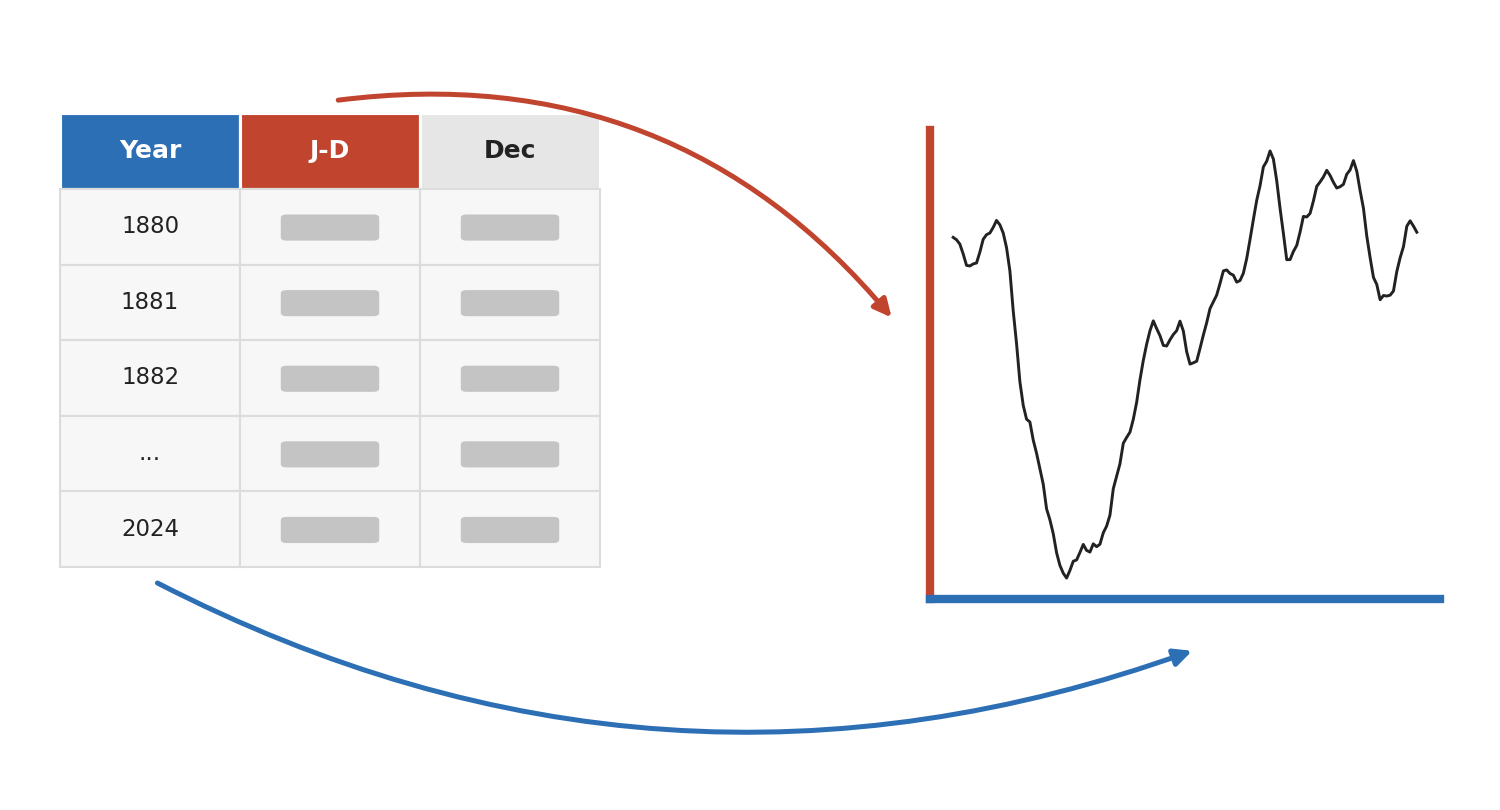

**Exercise C.1:** As a screen, talk through what your instructions to the AI should say. Then write them in the cell below, replacing the example text, and run it.

In [ ]:
instructions = """
Write your instructions here.
They can be several lines long.
"""

answer = ai.generate_text(instructions)
print(answer)

**Exercise C.2:** Copy the AI's code into the cell below, replace `plt.show()` with `check_plot(1)`, and run it. If something failed, work out what your instructions did not make clear, fix them in C.1, and go again until it passes.

In [ ]:
# Your code here

**Exercise C.3:** In one sentence: what did you have to add to your instructions to make it pass? (If it passed the first time, which part of your instructions mattered most?)

*Your answer here.*

### The second plot

Here is the next one. Look carefully at what is in this picture that was not in the last one.

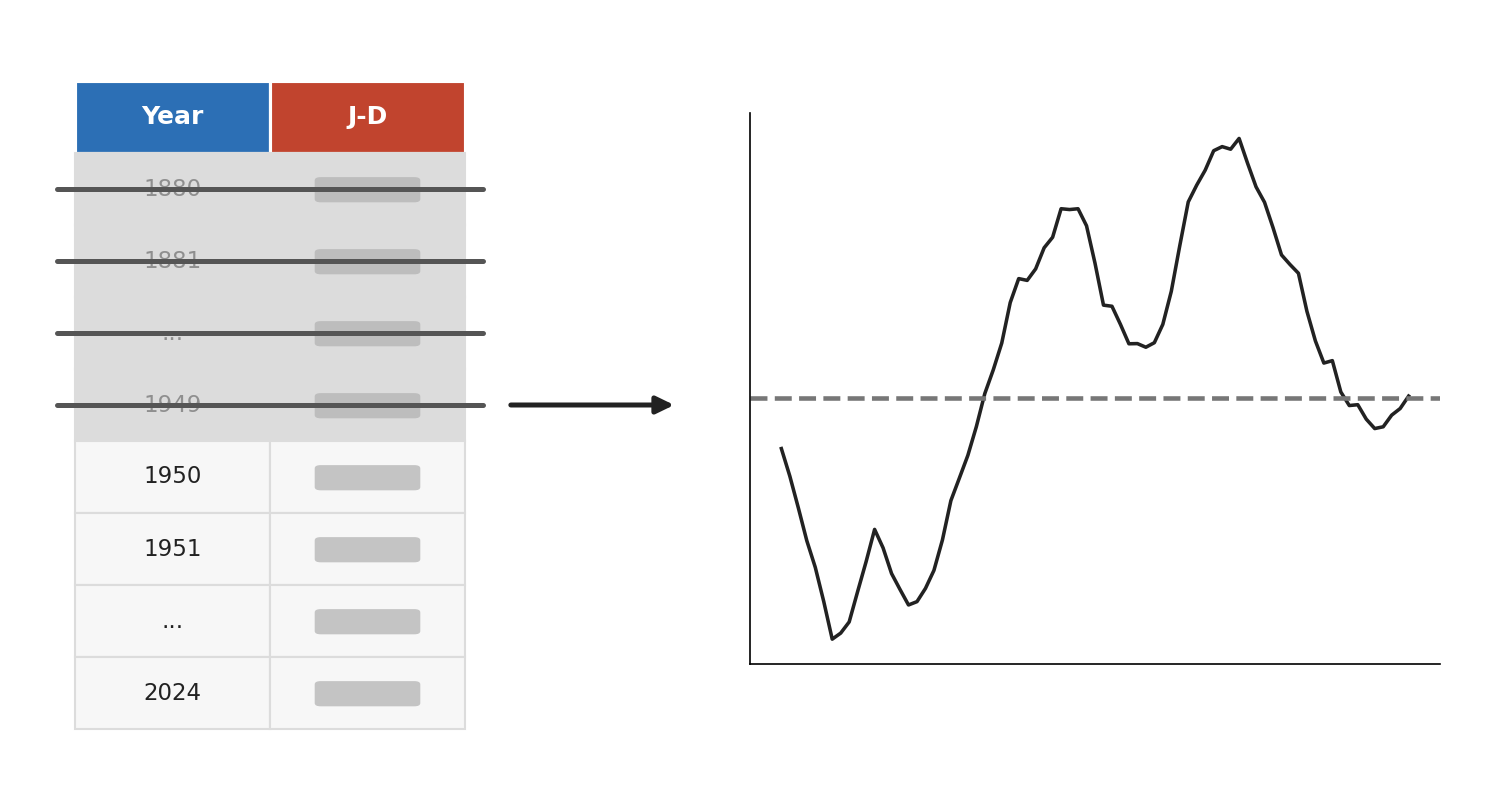

**Exercise C.4:** Write your instructions for this plot, and run them. **NOTE:** "recent years" is not something a computer can act on. Which years, exactly?

In [ ]:
instructions = """
Write your instructions here.
"""

answer = ai.generate_text(instructions)
print(answer)

**Exercise C.5:** Copy the AI's code into the cell below, replace `plt.show()` with `check_plot(2)`, and keep going until it passes.

In [ ]:
# Your code here

### More changes of plan

Somewhere in your code there is now a line that looks something like this:

> ```python
> recent = tempdata[tempdata["Year"] >= 1950]
> ```

The part inside the outer square brackets, `tempdata["Year"] >= 1950`, asks a true-or-false question about every row of the table: "is this year 1950 or later?" The outer brackets then keep only the rows where the answer is true. It is like sorting a pile of exam papers by asking "is this score above 50?" and keeping only the "yes" pile. (The AI may have used a different name than `recent`. That's fine.)

Now we have changed our minds, three times:

- (a) Start from **1990** instead of 1950.
- (b) Put the dashed line at **0.5** instead of 0.
- (c) Show **December** instead of the whole year.

**Exercise C.6:** Before you change anything, write which line of your code you think each change needs, in one line each. Then make the changes, running after each one. Were you right?

*Your answer here.*

In [ ]:
# Your code here

### Optional, if you finish early: Are recent years warmer?

This is the question the whole unit has been building up to. Here is a target, but the right-hand side is empty. That part is yours.

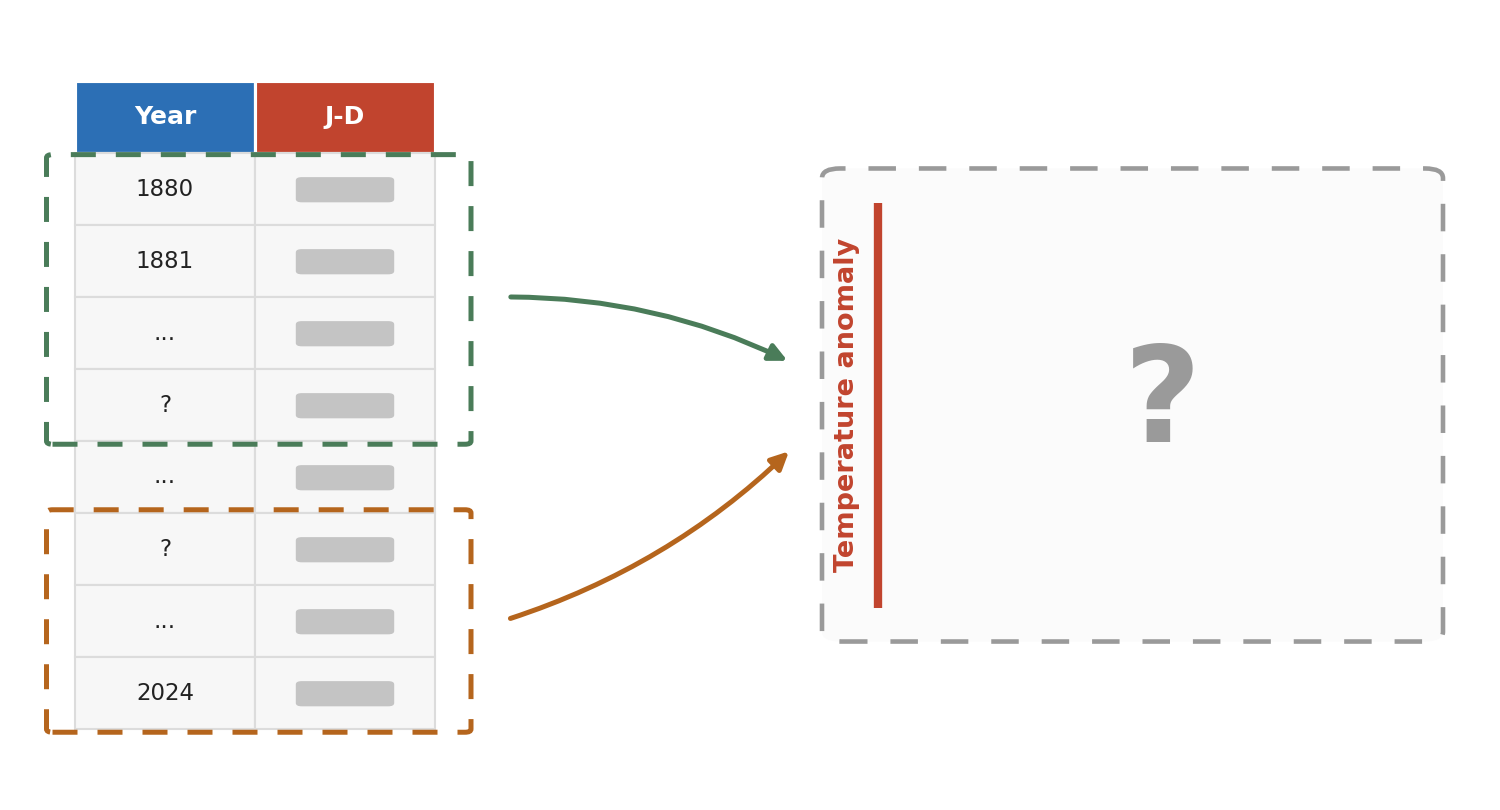

**Exercise C.7:** *(Optional.)* Decide as a screen: which years count as "early" and which count as "recent"? What will you do with each group of numbers so you can put the two side by side? (Think back to class 5.2.) What kind of plot will show it? Write your decisions briefly, then write your instructions and get your plot. There is no checker for this one.

In [ ]:
# Your code here

*Your answer here.*

🛑 **Stop!** 🛑

Look up at the front. We will look at some instructions together, and at what the ones that worked had in common.

## Summary

Today you:

1. **Looked at a real NASA data file** as plain text, and found its extra top line and its missing values.
2. **Got the file into Python**: into your Drive, Drive mounted in Colab, and read with `pd.read_csv`.
3. **Described plots for an AI to build**, and found out how exact a description has to be.
4. **Changed your mind**, and found out whether it was faster to ask the AI again or to change the code yourselves.

### Key takeaways

- **To read a file from your Drive:** import the libraries, `drive.mount('/content/drive')`, then `pd.read_csv(path)`. You will do this again on Thursday.
- **Square brackets get one piece:** `tempdata["J-D"]` is one column of the table.
- **Good instructions name things:** which data, which columns, which kind of plot, which years (as a number), and anything extra, like labels, a title, or a line.

## Important: Submission Instructions

1. Check that you have completed all the exercises.
2. Check that the notebook is shared as an **Editor** with everyone in your screen and the instructor.
3. **Each of you** submits on Canvas: paste the notebook link into the **Website URL** box, and in the **Comments** box write whether you drove today (**Drove**, **Didn't drive**, or **N/A**). Everyone in your screen submits the same link.

## Appendix: Without Google Drive (optional)

**This is only for people who do not want to connect Colab to their Google Drive.** Everyone else, use the Drive steps in Part B.

You can upload a file straight into your Colab session instead:

1. Click the **folder icon** on the left side of Colab, to open the file browser.
2. Click the **Upload** button at the top of the file browser (a page with an arrow pointing up), and choose `NH.Ts+dSST.csv` from your laptop.
3. Skip "Mounting Google Drive." When you read the file, the path is just the file's name:

```python
tempdata = pd.read_csv("NH.Ts+dSST.csv", skiprows=1, na_values="***")
```

**NOTE:** Files uploaded this way are deleted when your Colab session ends, for example when you close the notebook or leave it alone for a while. Each time you come back, you have to upload the file again before you run the notebook.

# Credits

This notebook contains materials created by Ethan Brown (with assistance from Google Gemini, before I kept track; and more recently from Claude, [see conversation](https://claude.ai/share/6f6b438f-9470-44db-bec5-7c0e8cd50c06)), Nguyen Cao Nghi, [Allen Downey](https://allendowney.github.io/ElementsOfDataScience/),  Sebastian Dziallas, and Trung Phan .